# Humanitarian Giving Observatory — SQL + pandas

**Portfolio notebook | DuckDB SQL → pandas → visual analysis**

This notebook recreates the repository's core analysis of reported humanitarian funding against recorded requirements. It is designed to be run from top to bottom in **Google Colab** and to make the SQL and pandas contributions easy to explain in a portfolio interview.

> **Interpretation boundary:** this is a descriptive analysis of reported financial records. It does not measure humanitarian need, severity, people affected, suffering, funding impact, or donor intent. Blank requirements are unknown in this extract, not zero need.

### What you will demonstrate

1. Load and preserve raw CSV data, then clean types and codes with SQL.
2. Audit missing values and reporting-year coverage.
3. Build reusable SQL tables/views and calculate KPIs with aggregations, CTEs, `CASE`, joins, and a window function.
4. Move query results into pandas, validate totals, inspect results, and make charts.
5. Explain the aligned-period scope and the denominator-completeness caveat.

The notebook is pinned to the repository snapshot at commit `3790dac86af3141ae9309c0d493305e26581bda2` so results are reproducible even if the repository's `main` branch changes later.

## 1. Install and import the tools

DuckDB provides an in-process SQL engine. We use SQL for source preparation and analytical aggregations, then pandas for result handling and plotting.

In [1]:
%pip -q install duckdb pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import urllib.request
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

START_YEAR, END_YEAR = 2000, 2026
SNAPSHOT_COMMIT = "3790dac86af3141ae9309c0d493305e26581bda2"
RAW = f"https://raw.githubusercontent.com/valentinTe93/humanitarian-giving-observatory/{SNAPSHOT_COMMIT}/data"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# Use local repository data if present; otherwise fetch the pinned snapshot.
FILES = {
    "fts_requirements_funding_global.csv": f"{RAW}/fts_requirements_funding_global.csv",
    "country_codes_iso3.csv": f"{RAW}/country_codes_iso3.csv",
}
for filename, url in FILES.items():
    target = DATA_DIR / filename
    if not target.exists():
        print(f"Downloading {filename} …")
        urllib.request.urlretrieve(url, target)

FTS_PATH = (DATA_DIR / "fts_requirements_funding_global.csv").resolve()
LOOKUP_PATH = (DATA_DIR / "country_codes_iso3.csv").resolve()
print(f"FTS source: {FTS_PATH.name} ({FTS_PATH.stat().st_size:,} bytes)")
print(f"Country lookup: {LOOKUP_PATH.name} ({LOOKUP_PATH.stat().st_size:,} bytes)")
print("Pinned repository snapshot:", "3790dac86af3141ae9309c0d493305e26581bda2")

FTS source: fts_requirements_funding_global.csv (278,750 bytes)
Country lookup: country_codes_iso3.csv (11,453 bytes)
Pinned repository snapshot: 3790dac86af3141ae9309c0d493305e26581bda2


## 2. Load raw files and create clean SQL tables

The raw staging table reads every column as text so the source representation is preserved. The clean fact table standardizes country codes and explicitly converts year and financial columns. `TRY_CAST` prevents malformed values from crashing the load; failed conversions become `NULL` and can be audited.

In [3]:
con = duckdb.connect(database=":memory:")

# Raw input: preserve source fields as text before transformation.
con.execute(f"""
    CREATE OR REPLACE TABLE raw_funding AS
    SELECT * FROM read_csv_auto('{FTS_PATH.as_posix()}', header = true, all_varchar = true)
""")
con.execute(f"""
    CREATE OR REPLACE TABLE raw_location_lookup AS
    SELECT * FROM read_csv_auto('{LOOKUP_PATH.as_posix()}', header = true, all_varchar = true)
""")

# Clean analytical fact. Keep source records at their original record grain;
# do not invent a synthetic plan key for rows where the source plan id is blank.
con.execute("""
    CREATE OR REPLACE TABLE fact_funding AS
    SELECT
        upper(trim(countryCode)) AS country_code,
        try_cast(nullif(trim(id), '') AS INTEGER) AS plan_id,
        nullif(trim(name), '') AS plan_name,
        nullif(trim(code), '') AS plan_code,
        try_cast(nullif(trim(typeId), '') AS INTEGER) AS plan_type_id,
        nullif(trim(typeName), '') AS plan_type_name,
        try_cast(nullif(trim(year), '') AS INTEGER) AS reporting_year,
        try_cast(nullif(trim(requirements), '') AS DOUBLE) AS requirements_usd,
        try_cast(nullif(trim(funding), '') AS DOUBLE) AS reported_funding_usd,
        try_cast(nullif(trim(percentFunded), '') AS DOUBLE) AS source_percent_funded
    FROM raw_funding
""")

con.execute("""
    CREATE OR REPLACE TABLE dim_location AS
    SELECT DISTINCT
        upper(trim(location_code)) AS location_code,
        nullif(trim(country_name), '') AS country_name,
        upper(nullif(trim(iso_alpha_3), '')) AS iso_alpha_3,
        nullif(trim(region), '') AS region,
        nullif(trim(sub_region), '') AS sub_region
    FROM raw_location_lookup
    WHERE nullif(trim(location_code), '') IS NOT NULL
""")

print("Raw records:", con.execute("SELECT count(*) FROM raw_funding").fetchone()[0])
print("Clean fact records:", con.execute("SELECT count(*) FROM fact_funding").fetchone()[0])
print("Location lookup rows:", con.execute("SELECT count(*) FROM dim_location").fetchone()[0])

Raw records: 3848
Clean fact records: 3848
Location lookup rows: 249


## 3. SQL data-quality audit

This single query checks row count, year range, missing key measures, and whether funding appears on rows without a recorded requirement. This is important because the headline ratio follows the source model: sum of funding divided by sum of requirements, not a row-level match rate.

In [4]:
quality_sql = """
SELECT
    count(*) AS row_count,
    min(reporting_year) AS first_year,
    max(reporting_year) AS last_year,
    count(*) FILTER (WHERE requirements_usd IS NULL) AS blank_requirement_rows,
    count(*) FILTER (WHERE reported_funding_usd IS NULL) AS blank_funding_rows,
    count(*) FILTER (WHERE source_percent_funded IS NULL) AS blank_source_percent_rows,
    count(*) FILTER (WHERE requirements_usd < 0) AS negative_requirement_rows,
    count(*) FILTER (WHERE reported_funding_usd < 0) AS negative_funding_rows
FROM fact_funding
"""
quality_df = con.execute(quality_sql).df()
display(quality_df)

completeness_sql = """
SELECT
    count(*) AS aligned_period_rows,
    count(*) FILTER (WHERE requirements_usd IS NOT NULL) AS rows_with_requirement,
    count(*) FILTER (WHERE reported_funding_usd IS NOT NULL) AS rows_with_funding,
    sum(coalesce(reported_funding_usd, 0)) FILTER (
        WHERE requirements_usd IS NULL
    ) AS funding_on_rows_with_blank_requirement_usd
FROM fact_funding
WHERE reporting_year BETWEEN 2000 AND 2026
"""
completeness_df = con.execute(completeness_sql).df()
display(completeness_df)

# Show country codes that did not match the provided lookup rather than assigning names.
unmatched_sql = """
SELECT f.country_code, count(*) AS source_rows
FROM fact_funding AS f
LEFT JOIN dim_location AS d ON f.country_code = d.location_code
WHERE f.country_code IS NOT NULL AND d.location_code IS NULL
GROUP BY f.country_code
ORDER BY source_rows DESC, f.country_code
"""
unmatched_df = con.execute(unmatched_sql).df()
print("Unmatched source country codes:", len(unmatched_df))
display(unmatched_df.head(10))

,row_count,first_year,last_year,blank_requirement_rows,blank_funding_rows,blank_source_percent_rows,negative_requirement_rows,negative_funding_rows
0,3848,1999,2031,2655,19,2668,0,7


,aligned_period_rows,rows_with_requirement,rows_with_funding,funding_on_rows_with_blank_requirement_usd
0,3662,1193,3643,1.403715e+11


Unmatched source country codes: 0


,country_code,source_rows


## 4. SQL KPIs: aligned period versus all records

The main report uses **2000–2026**, the years with requirement records in this snapshot. A separate all-record row reproduces the Power BI validation context, which also includes funding-only years outside that range. Keep these scopes separate when explaining results.

The ratio is calculated as `SUM(reported funding) / SUM(requirements)`. The source `percentFunded` is retained for reference and is not averaged or summed.

In [5]:
headline_sql = """
WITH scopes AS (
    SELECT 'Aligned period (2000–2026)' AS scope, *
    FROM fact_funding
    WHERE reporting_year BETWEEN 2000 AND 2026
    UNION ALL
    SELECT 'All records' AS scope, *
    FROM fact_funding
), totals AS (
    SELECT
        scope,
        count(*) AS row_count,
        sum(coalesce(requirements_usd, 0)) AS requirements_usd,
        sum(coalesce(reported_funding_usd, 0)) AS reported_funding_usd,
        sum(coalesce(reported_funding_usd, 0))
            FILTER (WHERE requirements_usd IS NULL) AS funding_on_blank_requirement_usd
    FROM scopes
    GROUP BY scope
)
SELECT
    scope,
    row_count,
    requirements_usd,
    reported_funding_usd,
    requirements_usd - reported_funding_usd AS funding_gap_usd,
    100.0 * reported_funding_usd / nullif(requirements_usd, 0) AS coverage_pct,
    funding_on_blank_requirement_usd
FROM totals
ORDER BY CASE scope WHEN 'Aligned period (2000–2026)' THEN 1 ELSE 2 END
"""
headline_df = con.execute(headline_sql).df()
display(headline_df.style.format({
    "requirements_usd": "${:,.0f}",
    "reported_funding_usd": "${:,.0f}",
    "funding_gap_usd": "${:,.0f}",
    "coverage_pct": "{:.2f}%",
    "funding_on_blank_requirement_usd": "${:,.0f}",
}))

,scope,row_count,requirements_usd,reported_funding_usd,funding_gap_usd,coverage_pct,funding_on_blank_requirement_usd
0,Aligned period (2000–2026),3662,"$531,384,487,620","$428,916,313,198","$102,468,174,422",80.72%,"$140,371,534,744"
1,All records,3848,"$531,384,487,620","$430,833,765,703","$100,550,721,917",81.08%,"$142,288,987,249"


## 5. Annual trend with SQL aggregation

The annual query uses `GROUP BY` and conditional counts to produce additive totals and completeness counts. Coverage is recalculated from those annual totals. Values above 100% remain visible, and 2026 should be treated as provisional because only part of its records have a requirement amount in this snapshot.

In [6]:
annual_sql = """
SELECT
    reporting_year,
    count(*) AS source_rows,
    count(*) FILTER (WHERE requirements_usd IS NOT NULL) AS rows_with_requirement,
    count(*) FILTER (WHERE reported_funding_usd IS NOT NULL) AS rows_with_funding,
    sum(coalesce(requirements_usd, 0)) AS requirements_usd,
    sum(coalesce(reported_funding_usd, 0)) AS reported_funding_usd,
    100.0 * sum(coalesce(reported_funding_usd, 0))
        / nullif(sum(coalesce(requirements_usd, 0)), 0) AS coverage_pct
FROM fact_funding
WHERE reporting_year BETWEEN 2000 AND 2026
GROUP BY reporting_year
ORDER BY reporting_year
"""
annual_df = con.execute(annual_sql).df()
display(annual_df.tail(8).style.format({
    "requirements_usd": "${:,.0f}",
    "reported_funding_usd": "${:,.0f}",
    "coverage_pct": "{:.1f}%",
}))

,reporting_year,source_rows,rows_with_requirement,rows_with_funding,requirements_usd,reported_funding_usd,coverage_pct
19,2019,147,39,147,"$26,708,350,809","$22,912,775,123",85.8%
20,2020,196,72,196,"$34,710,850,215","$25,120,449,721",72.4%
21,2021,184,76,181,"$37,751,115,205","$28,083,778,954",74.4%
22,2022,190,77,188,"$50,091,454,758","$37,650,987,686",75.2%
23,2023,195,85,194,"$55,820,524,615","$33,029,332,782",59.2%
24,2024,203,91,203,"$49,196,037,773","$31,693,460,520",64.4%
25,2025,194,86,191,"$45,333,142,021","$23,738,426,187",52.4%
26,2026,164,45,160,"$31,490,846,501","$17,168,262,354",54.5%


## 6. Geographic SQL analysis: join, `CASE`, and window ranking

The country-code lookup is joined after aggregating the fact table. We calculate total requirements and funding first, then coverage and positive shortfall. A SQL `CASE` assigns the same four coverage bands used in the project. The ranking query uses `ROW_NUMBER()` to select the top 10 positive shortfalls.

In [7]:
country_sql = """
WITH country_totals AS (
    SELECT
        f.country_code,
        sum(coalesce(f.requirements_usd, 0)) AS requirements_usd,
        sum(coalesce(f.reported_funding_usd, 0)) AS reported_funding_usd
    FROM fact_funding AS f
    WHERE f.reporting_year BETWEEN 2000 AND 2026
      AND f.country_code IS NOT NULL
    GROUP BY f.country_code
), enriched AS (
    SELECT
        c.country_code,
        coalesce(d.country_name, c.country_code) AS country_name,
        d.iso_alpha_3,
        d.region,
        d.sub_region,
        c.requirements_usd,
        c.reported_funding_usd,
        c.requirements_usd - c.reported_funding_usd AS funding_gap_usd,
        greatest(c.requirements_usd - c.reported_funding_usd, 0) AS positive_shortfall_usd,
        100.0 * c.reported_funding_usd / nullif(c.requirements_usd, 0) AS coverage_pct
    FROM country_totals AS c
    LEFT JOIN dim_location AS d ON c.country_code = d.location_code
)
SELECT *,
    CASE
        WHEN coverage_pct IS NULL THEN 'No positive requirement denominator'
        WHEN coverage_pct < 50 THEN 'Below 50%'
        WHEN coverage_pct < 80 THEN '50% to below 80%'
        WHEN coverage_pct < 100 THEN '80% to below 100%'
        ELSE '100% or above'
    END AS coverage_band
FROM enriched
ORDER BY country_code
"""
country_df = con.execute(country_sql).df()

ranked_sql = """
WITH country_totals AS (
    SELECT
        f.country_code,
        sum(coalesce(f.requirements_usd, 0)) AS requirements_usd,
        sum(coalesce(f.reported_funding_usd, 0)) AS reported_funding_usd
    FROM fact_funding AS f
    WHERE f.reporting_year BETWEEN 2000 AND 2026
      AND f.country_code IS NOT NULL
    GROUP BY f.country_code
), ranked AS (
    SELECT
        c.country_code,
        coalesce(d.country_name, c.country_code) AS country_name,
        c.requirements_usd,
        c.reported_funding_usd,
        greatest(c.requirements_usd - c.reported_funding_usd, 0) AS positive_shortfall_usd,
        row_number() OVER (
            ORDER BY greatest(c.requirements_usd - c.reported_funding_usd, 0) DESC,
                     c.country_code
        ) AS shortfall_rank
    FROM country_totals AS c
    LEFT JOIN dim_location AS d ON c.country_code = d.location_code
)
SELECT * FROM ranked
WHERE positive_shortfall_usd > 0 AND shortfall_rank <= 10
ORDER BY shortfall_rank
"""
top10_df = con.execute(ranked_sql).df()

display(country_df[["country_code", "country_name", "requirements_usd", "reported_funding_usd", "coverage_pct", "coverage_band"]].head(12))
display(top10_df[["shortfall_rank", "country_name", "requirements_usd", "reported_funding_usd", "positive_shortfall_usd"]].style.format({
    "requirements_usd": "${:,.0f}",
    "reported_funding_usd": "${:,.0f}",
    "positive_shortfall_usd": "${:,.0f}",
}))

,country_code,country_name,requirements_usd,reported_funding_usd,coverage_pct,coverage_band
0,AFG,Afghanistan,2.607434e+10,2.168479e+10,83.165256,80% to below 100%
1,AGO,Angola,1.358477e+09,1.298565e+09,95.589800,80% to below 100%
2,AIA,Anguilla,0.000000e+00,7.591600e+05,NaN,No positive requirement denominator
3,ARG,Argentina,1.416813e+08,5.640744e+07,39.812914,Below 50%
4,BDI,Burundi,2.215851e+09,1.872759e+09,84.516482,80% to below 100%
5,BEN,Benin,3.250463e+07,9.923393e+07,305.291677,100% or above
6,BFA,Burkina Faso,6.186815e+09,3.484009e+09,56.313458,50% to below 80%
7,BGD,Bangladesh,9.111086e+09,8.081957e+09,88.704646,80% to below 100%
8,BGR,Bulgaria,1.118304e+08,3.315542e+07,29.647940,Below 50%
9,BHS,Bahamas,0.000000e+00,3.756345e+07,NaN,No positive requirement denominator


,shortfall_rank,country_name,requirements_usd,reported_funding_usd,positive_shortfall_usd
0,1,Lebanon,"$33,627,571,977","$16,827,477,260","$16,800,094,717"
1,2,Syria,"$49,024,335,855","$35,532,465,650","$13,491,870,205"
2,3,Sudan,"$39,409,006,566","$27,066,965,497","$12,342,041,069"
3,4,Congo - Kinshasa,"$29,081,282,637","$18,058,490,126","$11,022,792,511"
4,5,Türkiye,"$14,556,634,239","$8,909,676,772","$5,646,957,467"
5,6,Somalia,"$24,512,060,611","$19,274,690,963","$5,237,369,648"
6,7,Chad,"$13,362,738,864","$8,324,482,818","$5,038,256,046"
7,8,South Sudan,"$24,741,791,829","$19,910,060,545","$4,831,731,284"
8,9,Jordan,"$13,963,389,230","$9,546,843,663","$4,416,545,567"
9,10,Afghanistan,"$26,074,340,201","$21,684,791,710","$4,389,548,491"


## 7. Transfer SQL results into pandas and visualize

At this stage, SQL has produced the analytical result sets. Pandas is used to format them, derive compact display columns, and feed Matplotlib. The calculations remain aggregations of SQL output—not a second competing implementation of the business logic.

findfont: Failed to find font weight bold for Abyssinica SIL, now using 400.


findfont: Failed to find font weight bold for Lohit Devanagari, now using 400.


findfont: Failed to find font weight bold for Lohit Tamil, now using 400.


findfont: Failed to find font weight bold for Lohit Gujarati, now using 400.


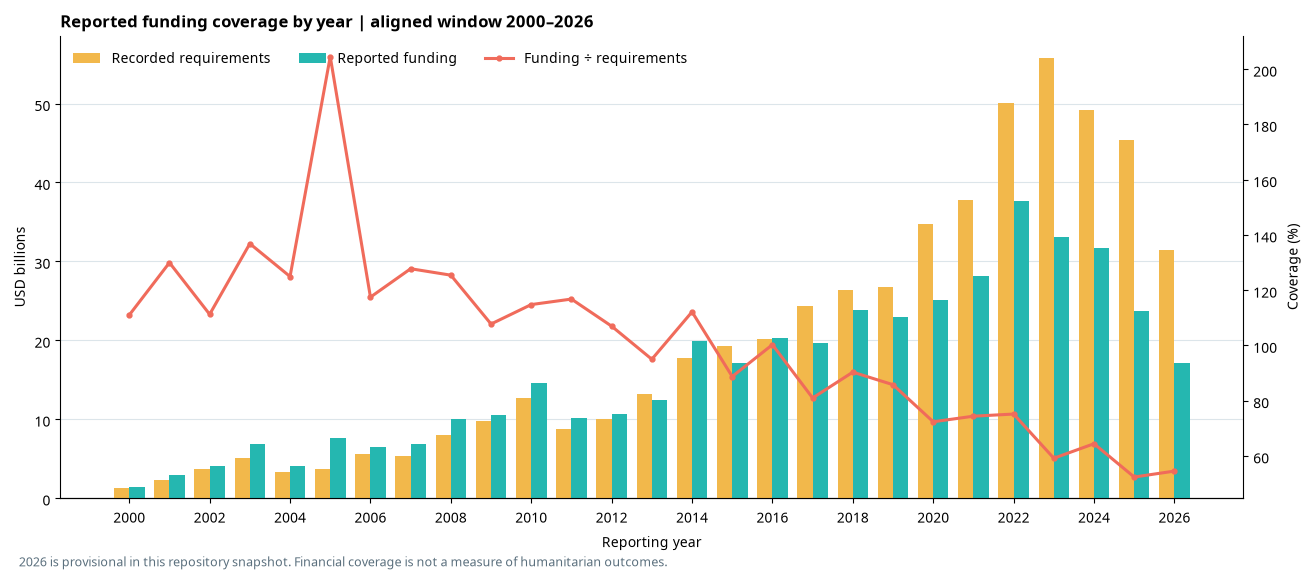

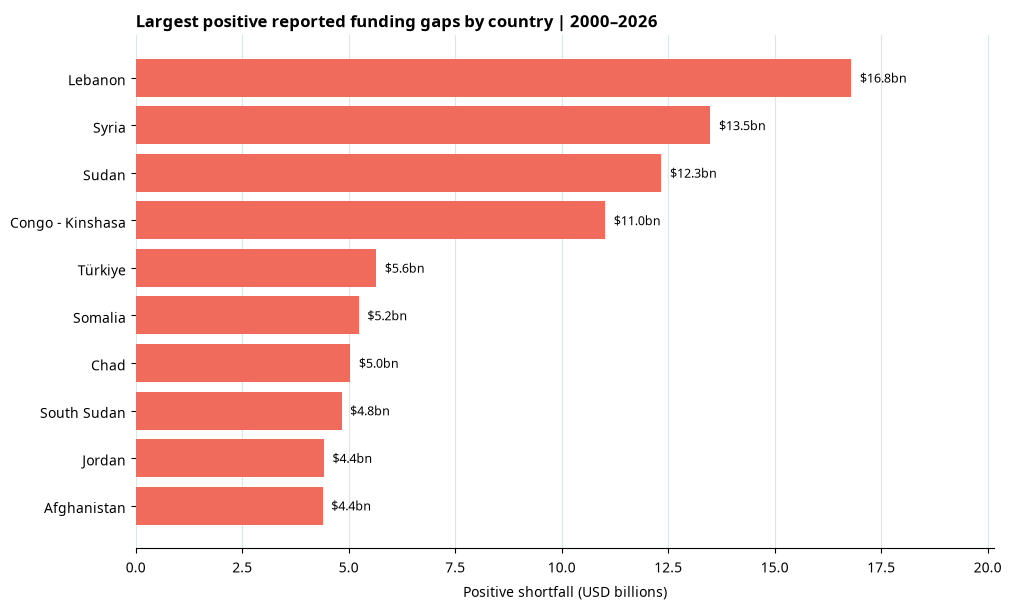

,coverage_band,location_count
0,Below 50%,15
1,50% to below 80%,29
2,80% to below 100%,13
3,100% or above,53
4,No positive requirement denominator,3


In [8]:
# Pandas display-oriented copies; USD billions are easier to read in charts.
annual_plot = annual_df.copy()
annual_plot["requirements_bn"] = annual_plot["requirements_usd"] / 1e9
annual_plot["funding_bn"] = annual_plot["reported_funding_usd"] / 1e9

fig, ax = plt.subplots(figsize=(13, 5.5), constrained_layout=True)
width = 0.38
x = annual_plot["reporting_year"]
ax.bar(x - width / 2, annual_plot["requirements_bn"], width,
       color="#F2B84B", label="Recorded requirements", zorder=3)
ax.bar(x + width / 2, annual_plot["funding_bn"], width,
       color="#25B7B0", label="Reported funding", zorder=3)
ax.set_ylabel("USD billions")
ax.set_xlabel("Reporting year")
ax.set_xticks(annual_plot["reporting_year"][::2])
ax.grid(axis="y", color="#DCE5EA", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax2 = ax.twinx()
ax2.plot(x, annual_plot["coverage_pct"], color="#F06B5B", marker="o",
         markersize=3.5, linewidth=2.2, label="Funding ÷ requirements", zorder=4)
ax2.set_ylabel("Coverage (%)")
ax2.spines[["top", "left"]].set_visible(False)
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, loc="upper left", frameon=False, ncol=3)
ax.set_title("Reported funding coverage by year | aligned window 2000–2026", loc="left", weight="bold")
fig.text(0.01, -0.02,
         "2026 is provisional in this repository snapshot. Financial coverage is not a measure of humanitarian outcomes.",
         color="#5A6F7D", fontsize=9)
plt.show()

# Horizontal top-10 positive shortfall chart.
plot_top10 = top10_df.sort_values("positive_shortfall_usd", ascending=True).copy()
plot_top10["shortfall_bn"] = plot_top10["positive_shortfall_usd"] / 1e9
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.barh(plot_top10["country_name"], plot_top10["shortfall_bn"], color="#F06B5B")
ax.set_xlabel("Positive shortfall (USD billions)")
ax.set_title("Largest positive reported funding gaps by country | 2000–2026", loc="left", weight="bold")
ax.grid(axis="x", color="#DCE5EA", zorder=0)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
for y, val in enumerate(plot_top10["shortfall_bn"]):
    ax.text(val + plot_top10["shortfall_bn"].max() * 0.012, y, f"${val:.1f}bn", va="center", fontsize=9)
ax.set_xlim(0, plot_top10["shortfall_bn"].max() * 1.2)
plt.show()

# SQL-generated band distribution, summarized in pandas for a concise portfolio table.
band_order = ["Below 50%", "50% to below 80%", "80% to below 100%", "100% or above", "No positive requirement denominator"]
band_counts = (country_df["coverage_band"].value_counts()
               .reindex(band_order, fill_value=0)
               .rename_axis("coverage_band").reset_index(name="location_count"))
display(band_counts)

## 8. Reconciliation and interpretation

Use this section to explain why your totals match the existing Power BI/Excel analysis and why the funding ratio needs qualification.

In [9]:
aligned = headline_df.loc[headline_df["scope"] == "Aligned period (2000–2026)"].iloc[0]
all_records = headline_df.loc[headline_df["scope"] == "All records"].iloc[0]

print(f"Aligned requirements: ${aligned['requirements_usd'] / 1e9:,.2f}bn")
print(f"Aligned reported funding: ${aligned['reported_funding_usd'] / 1e9:,.2f}bn")
print(f"Aligned gap: ${aligned['funding_gap_usd'] / 1e9:,.2f}bn")
print(f"Aligned aggregate coverage: {aligned['coverage_pct']:.2f}%")
print(f"All-record validation coverage: {all_records['coverage_pct']:.2f}%")
print(f"Funding on blank-requirement rows in aligned period: ${aligned['funding_on_blank_requirement_usd'] / 1e9:,.2f}bn")

# Snapshot-based assertions catch unintended changes in the analytical logic.
assert round(aligned["requirements_usd"] / 1e9, 2) == 531.38
assert round(aligned["reported_funding_usd"] / 1e9, 2) == 428.92
assert round(aligned["coverage_pct"], 2) == 80.72
assert round(all_records["reported_funding_usd"] / 1e9, 2) == 430.83
assert top10_df.iloc[0]["country_name"] == "Lebanon"

latest = annual_df.loc[annual_df["reporting_year"] == 2026].iloc[0]
print(f"2026 completeness: {int(latest['rows_with_requirement'])} of {int(latest['source_rows'])} records have a requirement amount")
print("Reconciliation checks passed.")

Aligned requirements: $531.38bn
Aligned reported funding: $428.92bn
Aligned gap: $102.47bn
Aligned aggregate coverage: 80.72%
All-record validation coverage: 81.08%
Funding on blank-requirement rows in aligned period: $140.37bn
2026 completeness: 45 of 164 records have a requirement amount
Reconciliation checks passed.


### How to explain the denominator caveat

The reported aggregate coverage measure is the sum of reported funding divided by the sum of recorded requirements. In the aligned period, a substantial amount of funding is attached to rows whose requirement value is blank. The calculation retains that funding in the numerator while blank requirements do not add to the denominator. Therefore, the result reproduces the documented dashboard measure, but it should not be described as a row-matched share of fully observed requirements.

### Portfolio takeaways

- **SQL:** raw/staging tables, type conversion, missingness audits, CTEs, conditional aggregation, `LEFT JOIN`, `CASE`, `GROUP BY`, and a window function.
- **Python/pandas:** query-result handling, display formatting, derived chart units, rankings display, and visualizations.
- **Analytical judgment:** scope reconciliation, source completeness checks, retention of ratios above 100%, and careful interpretation of financial shortfalls.

### Sources and project files

- [Humanitarian Giving Observatory repository](https://github.com/valentinTe93/humanitarian-giving-observatory)
- [Project report](https://github.com/valentinTe93/humanitarian-giving-observatory/blob/main/Report.md)
- [Process documentation](https://github.com/valentinTe93/humanitarian-giving-observatory/blob/main/docs/Process_documentation.pdf)
- Data files used here: `data/fts_requirements_funding_global.csv` and `data/country_codes_iso3.csv` from the pinned repository snapshot.

**Reminder:** this analysis describes reported financial records. It is not a measure of humanitarian need or a recommendation for allocating aid.